# Big West Championship model: results

This notebook shows how well the model predicts the Big West Track & Field Championships, and how it
compares with the usual way of predicting a meet
Every number is computed here from `bigwest_model.py` and the data files, so the notebook can be rerun.

**What the model does.** Before the championship, it uses each athlete's regular-season marks to predict
how they will perform at Big West. It then simulates the whole meet 20,000 times, with each athlete
having good and bad days and a small chance of a bad race or no mark. Counting the points in each
simulated meet gives, for every athlete, event and team, a **range of likely outcomes** rather than one
number: for example, "UC Irvine scores 70–95 points, most likely about 82, and wins 3% of the time."

**What we compare it with: the performance list.** This is how coaches and fans usually predict a meet,
and what tools like the TFRRS meet calculator do. Rank every athlete by their season-best mark in each
event, give the top 8 the meet's points (10-8-6-5-4-3-2-1), and add up the points per team. It gives one
number per team with no uncertainty.

**Contents**
1. How the model is tested
2. What each accuracy measure means, with small examples
3. Results for the 2026 championship (the final test)
4. Team-by-team results for 2026
5. Results by event type
6. Results across seven seasons (leave-one-season-out)
7. Are the model's probabilities trustworthy? (calibration)
8. UC San Diego
9. Where the model struggles
10. Summary

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import bigwest_model as bm

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

REG_PATH = "../data/processed/regular_season.csv"
BW_PATH = "../data/processed/bigwest_2019_2026_results.csv"

CFG = dict(bm.CONFIG)                     # the final model (V13): all settings as in bigwest_model.py
reg = bm.load_regular(REG_PATH, CFG)      # regular-season marks
bw = bm.load_bigwest(BW_PATH, CFG)        # Big West championship results 2019, 2021-2026
cdates = bm.champ_dates(reg, sorted(bw["season"].unique()))
bw_events = {g: set(x["event"]) for g, x in bw.groupby("gender")}

MODEL, PLIST, ACTUAL = "#2a78d6", "#eb6834", "#0b0b0b"   # colors used in every chart
GENDER = {"M": "Men", "W": "Women"}
print("seasons:", [int(x) for x in sorted(bw["season"].unique())], "| championship results:", len(bw))

seasons: [2019, 2021, 2022, 2023, 2024, 2025, 2026] | championship results: 5257


## 1. How the model is tested

A prediction is only meaningful if it is tested on a championship the model has **not seen**. Two tests:

- **Final test: 2026.** The model learns from the 2019 and 2021–2025 championships (there was no 2020
  meet), then predicts 2026 using only regular-season marks from before the 2026 meet. 2026 was kept
  aside for the whole project and never used to make a modeling decision.
- **Robustness check: leave-one-season-out.** Repeat the same thing seven times: predict each season
  from 2019 to 2026 while learning from the other six. One good year could be luck; seven years show
  whether the model is consistently better.

In both tests the model simulates the athletes who actually entered that championship. The
performance list uses everyone with an outdoor mark in the event, as a coach would see it before entries
are declared.

In [2]:
r26 = bm.run_fold(reg, bw, *bm.FINAL_FOLD, cdates, bw_events, CFG, verbose=False)
s26 = r26["summary"]
tot26, te26, ath26 = r26["totals"], r26["team_event"], r26["athletes"]
print(f"2026: {len(ath26)} athlete-events, {len(te26)} team-events, "
      f"{tot26.groupby('gender').size().to_dict()} teams per gender")

2026: 853 athlete-events, 365 team-events, {'M': 10, 'W': 11} teams per gender


## 2. What each accuracy measure means

The model is judged at three levels, from smallest to largest: **athletes** (does this athlete score?),
**team-events** (how many points does a team get in one event?) and **team totals** (how many points
does a team get in the whole meet, and where does it finish?).

| Measure | Level | What it asks | Better is |
|---|---|---|---|
| **Brier score** | athlete | How good are the chances given for each athlete scoring (top 8)? | lower |
| **Mean absolute error (MAE)** | team-event, team total | On average, how many points off is the single best guess? | lower |
| **CRPS** | team-event, team total | How good is the whole predicted range, not just the best guess? | lower |
| **80% coverage** | team-event, team total | Does the real result land inside the model's 80% range about 80% of the time? | close to 80% |
| **Spearman rank correlation** | team total | Does it put the teams in the right finishing order? (1 = perfect) | higher |
| **Mark error** | athlete | How far is the predicted mark from the real one, in %? | lower |

The model and the performance list are compared on **Brier, MAE and Spearman**, because both give an
answer for those. CRPS, coverage and mark error only exist for the model: the performance list gives
no range, and it does not predict marks at the meet.

### Brier score: how good are the chances?

For every athlete in every event, the model gives a probability of scoring (placing top 8). The Brier
score is the average of *(probability − what happened)²*, where what happened is 1 if they scored and
0 if not. It is 0 for perfect predictions; always saying "50%" gives 0.25.

The performance list can only say "will score" (1) or "won't score" (0), so every wrong call costs the
full penalty of 1. The model's probabilities can hedge on athletes who are close to the cut.

In [3]:
example = pd.DataFrame({
    "athlete": ["clear favorite", "on the bubble", "on the bubble", "outsider"],
    "model chance": [0.95, 0.55, 0.55, 0.05],
    "list says": [1, 1, 0, 0],                 # seeded inside / outside the top 8
    "scored?": [1, 0, 1, 0],
})
example["model penalty"] = (example["model chance"] - example["scored?"]) ** 2
example["list penalty"] = (example["list says"] - example["scored?"]) ** 2
display(example)
print(f"Brier: model {example['model penalty'].mean():.3f} | performance list {example['list penalty'].mean():.3f}")

,athlete,model chance,list says,scored?,model penalty,list penalty
0,clear favorite,0.95,1,1,0.0025,0
1,on the bubble,0.55,1,0,0.3025,1
2,on the bubble,0.55,0,1,0.2025,1
3,outsider,0.05,0,0,0.0025,0


Brier: model 0.128 | performance list 0.500


### MAE: how far off is the best guess?

For a team in an event, or a team's meet total, the model's single best guess is the **median** of its
20,000 simulated meets (the middle value). The MAE is the average distance between that guess and the
real points. The performance list's guess is its own points total. The same measure is used for both,
so this is a direct comparison: "on average, the model's total was X points off, the list's Y."

### CRPS: how good is the whole predicted range?

The model gives a full range of outcomes, so its accuracy should depend on how much of that range sits
near the real result. The **continuous ranked probability score** (CRPS) measures this, in points:

- A forecast centered on the right answer with a narrow range scores close to 0.
- A forecast that is right on average but very wide is penalised for being vague.
- A narrow forecast in the wrong place is penalised most.

For a single number (like the performance list), the CRPS equals the absolute error, so CRPS and MAE are
on the same scale. The example below shows three forecasts of a team that really scored 105.

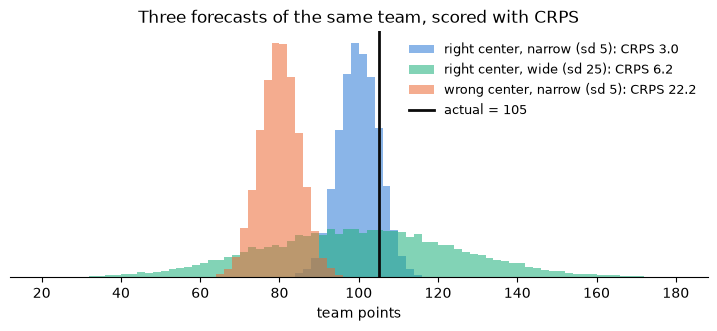

single number 100: CRPS 5.0 (= |105 - 100|)


In [4]:
rng = np.random.default_rng(0)
actual = 105
forecasts = {
    "right center, narrow (sd 5)": rng.normal(100, 5, 20000),
    "right center, wide (sd 25)": rng.normal(100, 25, 20000),
    "wrong center, narrow (sd 5)": rng.normal(80, 5, 20000),
    "single number: 100": np.full(20000, 100.0),
}
fig, ax = plt.subplots(figsize=(9, 3.2))
for (name, s), col in zip(list(forecasts.items())[:3], ["#2a78d6", "#1baf7a", "#eb6834"]):
    ax.hist(s, bins=80, range=(20, 180), density=True, alpha=0.55, color=col,
            label=f"{name}: CRPS {bm.crps(s, actual):.1f}")
ax.axvline(actual, color=ACTUAL, lw=2, label=f"actual = {actual}")
ax.set(xlabel="team points", yticks=[], title="Three forecasts of the same team, scored with CRPS")
ax.legend(frameon=False, fontsize=9, loc="upper right")
ax.spines[["top", "right", "left"]].set_visible(False)
plt.show()
print(f"single number 100: CRPS {bm.crps(forecasts['single number: 100'], actual):.1f} (= |105 - 100|)")

### 80% coverage and Spearman

- **80% coverage.** Every prediction comes with an 80% range: the 10th to 90th percentile of the simulated
  meets. If the ranges are honest, the real result lands inside them about 80% of the time. Much lower
  means the model is overconfident; much higher means the ranges are wider than needed.
- **Spearman rank correlation.** Compares the predicted finishing order of the teams with the real
  order. 1 means the order is exactly right; 0 means no relationship.

## 3. Results for the 2026 championship

The table compares the model with the performance list on every measure they share. "Model better"
is judged by the direction in the last column.

In [5]:
rows = [
    ("Athletes",     "Brier score (chance of scoring)",        s26["brier_model"],      s26["brier_plist"],      "lower"),
    ("Team-events",  "MAE, points per team per event",         s26["te_mae_model"],     s26["te_mae_plist"],     "lower"),
    ("Team totals",  "MAE, men's team totals (points)",        s26["M_total_mae_model"], s26["M_total_mae_plist"], "lower"),
    ("Team totals",  "MAE, women's team totals (points)",      s26["W_total_mae_model"], s26["W_total_mae_plist"], "lower"),
    ("Team order",   "Spearman, men's finishing order",        s26["M_spearman_model"], s26["M_spearman_plist"], "higher"),
    ("Team order",   "Spearman, women's finishing order",      s26["W_spearman_model"], s26["W_spearman_plist"], "higher"),
]
head26 = pd.DataFrame(rows, columns=["level", "measure", "model", "performance list", "better is"])
head26["model better?"] = np.where(head26["better is"] == "lower",
                                   head26["model"] < head26["performance list"],
                                   head26["model"] > head26["performance list"])
display(head26.round(3))

only = pd.DataFrame([
    ("Mark error (% from real mark)",          s26["mark_mae_pct"],      "lower"),
    ("CRPS, team-events (points)",              s26["te_crps_model"],     "lower"),
    ("CRPS, men's team totals (points)",        s26["M_total_crps_model"], "lower"),
    ("CRPS, women's team totals (points)",      s26["W_total_crps_model"], "lower"),
    ("80% coverage, team-events",               s26["te_cover80"],        "about 0.80"),
    ("80% coverage, men's team totals",         s26["M_total_cover80"],   "about 0.80"),
    ("80% coverage, women's team totals",       s26["W_total_cover80"],   "about 0.80"),
], columns=["model-only measure", "value", "target"])
display(only.round(3))

,level,measure,model,performance list,better is,model better?
0,Athletes,Brier score (chance of scoring),0.110,0.185,lower,True
1,Team-events,"MAE, points per team per event",1.622,1.898,lower,True
2,Team totals,"MAE, men's team totals (points)",8.600,14.200,lower,True
3,Team totals,"MAE, women's team totals (points)",14.182,10.455,lower,False
4,Team order,"Spearman, men's finishing order",0.988,0.891,higher,True
5,Team order,"Spearman, women's finishing order",0.902,0.936,higher,False


,model-only measure,value,target
0,Mark error (% from real mark),2.017,lower
1,"CRPS, team-events (points)",1.178,lower
2,"CRPS, men's team totals (points)",5.904,lower
3,"CRPS, women's team totals (points)",9.902,lower
4,"80% coverage, team-events",0.921,about 0.80
5,"80% coverage, men's team totals",0.800,about 0.80
6,"80% coverage, women's team totals",0.545,about 0.80


**Reading the 2026 results**

- **Athletes:** the model's Brier score is about 40% lower than the performance list's (0.110 vs 0.185).
  This is the clearest gain: the list is wrong about an athlete every time an upset happens around the
  8th-place cut, while the model's probabilities soften those misses.
- **Team-events:** the model's best guess is closer on average (1.62 vs 1.90 points per team per event).
- **Men's team totals:** much closer (8.6 vs 14.2 points off), and the finishing order is right except for
  one pair of teams (Spearman 0.99).
- **Women's team totals:** the performance list did better in 2026 (10.5 vs 14.2 points off, and a
  better finishing order). Section 6 shows that 2026 was one of the model's weaker women's seasons, and
  section 9 explains why.
- **Ranges:** 92% of team-event results land inside the model's 80% ranges, so those ranges are, if
  anything, slightly wide. For team totals, 8 of 10 men's teams land inside, but only 6 of 11
  women's teams.
- **Marks:** the predicted marks are about 2% from the real marks on average (for example, about 0.24 s
  in a 12-second 100 m).

## 4. Team-by-team results for 2026

Each row is one team. The model gives its best guess (median), an 80% range and the chance of winning
the meet. The chart shows the same thing: the blue bar is the model's 80% range, the blue dot its best
guess, the orange diamond the performance list and the black line the real score.

In [6]:
t = tot26.copy()
t["model error"] = t["med"] - t["actual"]
t["list error"] = t["plist_pts"] - t["actual"]
t["in 80% range"] = (t["actual"] >= t["lo80"]) & (t["actual"] <= t["hi80"])
show = (t.assign(**{"80% range": t["lo80"].round(0).astype(int).astype(str) + "–" + t["hi80"].round(0).astype(int).astype(str),
                    "chance to win": (100 * t["p_win"]).round(0).astype(int).astype(str) + "%"})
         [["gender", "team", "actual", "med", "80% range", "chance to win", "plist_pts", "model error", "list error", "in 80% range"]]
         .rename(columns={"med": "model best guess", "plist_pts": "performance list"})
         .sort_values(["gender", "actual"], ascending=[True, False]))
for g in ["M", "W"]:
    print(GENDER[g]); display(show[show["gender"] == g].drop(columns="gender").round(1).reset_index(drop=True))

Men


,team,actual,model best guess,80% range,chance to win,performance list,model error,list error,in 80% range
0,CAL POLY,201.5,181.0,164–198,96%,168.0,-20.5,-33.5,False
1,CAL ST. FULLERTON,152.0,143.0,125–162,4%,146.0,-9.0,-6.0,True
2,LONG BEACH ST.,114.0,122.0,104–140,0%,115.0,8.0,1.0,True
3,UC IRVINE,84.5,76.0,62–91,0%,67.0,-8.5,-17.5,True
4,UC SAN DIEGO,77.5,76.0,61–92,0%,66.0,-1.5,-11.5,True
5,UC SANTA BARBARA,66.5,74.0,60–89,0%,72.0,7.5,5.5,True
6,CSUN,46.0,67.0,54–81,0%,90.0,21.0,44.0,False
7,UC RIVERSIDE,44.0,40.0,28–53,0%,39.0,-4.0,-5.0,True
8,UC DAVIS,17.0,22.0,14–30,0%,32.0,5.0,15.0,True
9,CSU BAKERSFIELD,15.0,16.0,10–23,0%,18.0,1.0,3.0,True


Women


,team,actual,model best guess,80% range,chance to win,performance list,model error,list error,in 80% range
0,UC IRVINE,187.5,166.0,144–189,98%,178.0,-21.5,-9.5,True
1,CAL ST. FULLERTON,126.0,103.0,85–122,0%,114.0,-23.0,-12.0,False
2,CAL POLY,105.0,114.0,96–133,2%,120.0,9.0,15.0,True
3,UC SAN DIEGO,84.0,78.0,62–94,0%,72.0,-6.0,-12.0,True
4,LONG BEACH ST.,69.0,59.0,47–72,0%,62.0,-10.0,-7.0,True
5,CSUN,49.5,49.0,37–63,0%,49.0,-0.5,-0.5,True
6,UC SANTA BARBARA,49.5,72.0,56–90,0%,70.0,22.5,20.5,False
7,HAWAII,47.0,70.0,55–86,0%,58.0,23.0,11.0,False
8,UC RIVERSIDE,39.0,55.0,41–69,0%,50.0,16.0,11.0,False
9,CSU BAKERSFIELD,37.0,18.0,9–26,0%,23.0,-19.0,-14.0,False


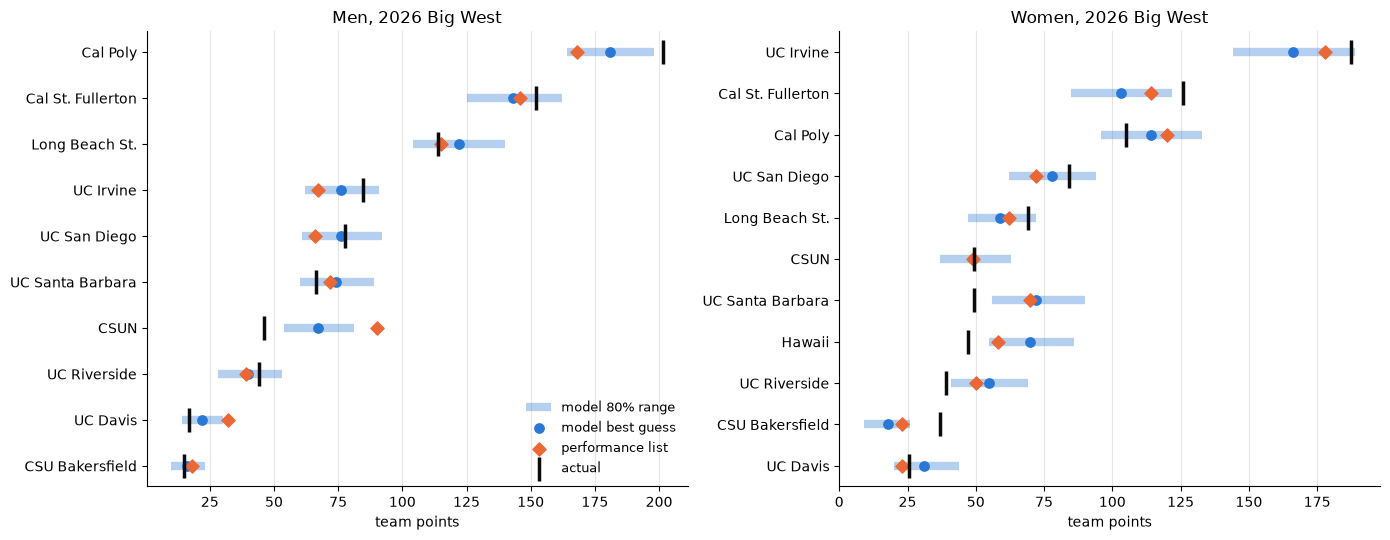

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, g in zip(axes, ["M", "W"]):
    d = t[t["gender"] == g].sort_values("actual").reset_index(drop=True)
    y = np.arange(len(d))
    ax.hlines(y, d["lo80"], d["hi80"], color=MODEL, lw=6, alpha=0.35, label="model 80% range")
    ax.scatter(d["med"], y, color=MODEL, s=45, zorder=3, label="model best guess")
    ax.scatter(d["plist_pts"], y, color=PLIST, marker="D", s=45, zorder=3, label="performance list")
    ax.scatter(d["actual"], y, color=ACTUAL, marker="|", s=300, lw=2.5, zorder=4, label="actual")
    ax.set_yticks(y, d["team"].str.title().str.replace("Uc ", "UC ").str.replace("Csun", "CSUN").str.replace("Csu ", "CSU "))
    ax.set(xlabel="team points", title=f"{GENDER[g]}, 2026 Big West")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", color="#e5e5e5")
axes[0].legend(frameon=False, loc="lower right", fontsize=9)
fig.tight_layout(); plt.show()

## 5. Results by event type

Average points error per team per event (MAE), split by kind of event. This shows where the gain over
the performance list comes from.

,model,performance list,n team-events
group,,,
relay,1.59,1.46,41
throw,1.34,1.67,70
sprint,1.76,1.95,92
horizontal,1.89,2.00,36
distance,1.27,2.39,88
vertical,2.03,2.66,29
multi,3.56,3.56,9


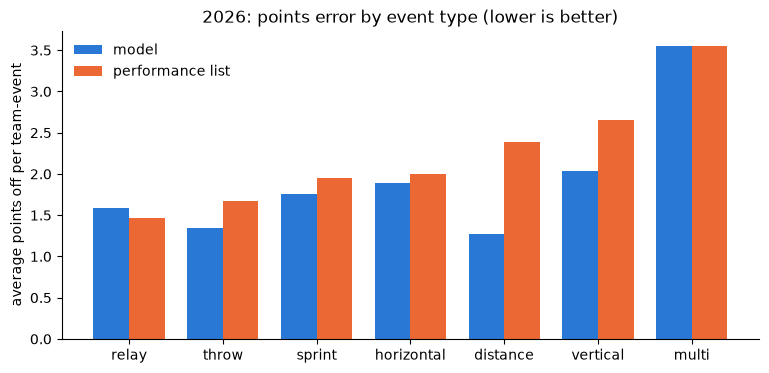

In [8]:
te = te26.copy()
te["group"] = te["event"].map(bm.event_group)
te["model"] = (te["med"] - te["actual"]).abs()
te["performance list"] = (te["plist_pts"] - te["actual"]).abs()
grp = te.groupby("group")[["model", "performance list"]].mean().sort_values("performance list")
grp["n team-events"] = te.groupby("group").size()
display(grp.round(2))

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(grp)); w = 0.38
ax.bar(x - w / 2, grp["model"], w, color=MODEL, label="model")
ax.bar(x + w / 2, grp["performance list"], w, color=PLIST, label="performance list")
ax.set_xticks(x, grp.index)
ax.set(ylabel="average points off per team-event", title="2026: points error by event type (lower is better)")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.show()

**Reading the event types (2026)**

- **Biggest gains: distance events and the high jump / pole vault.** One likely reason: in distance races the season-best
  list is often misleading, because some fast marks come from paced or early-season races, and some
  athletes enter several events. In the jumps over a bar, many athletes share similar bests and the
  list's strict ranking overstates how certain the order is.
- **Relays:** the performance list was slightly closer in 2026 (1.46 vs 1.59 points). Over the seven
  seasons the model is better on relays in 5 of 7 (section 6). The model predicts each relay from its
  season best, because teams run their strongest four at the championship, while early-season relays
  often use other lineups.
- **Heptathlon and decathlon** are tied in 2026 and favor the model in 5 of 7 seasons, but there are only
  a few team-events per year, so these numbers move a lot.

## 6. Results across seven seasons (leave-one-season-out)

The same comparison for every season from 2019 to 2026. For each season, the model learns from the
other six championships and predicts that one. This takes a few minutes to run.

In [9]:
ALL = sorted(int(s) for s in bw["season"].unique())
loso = {t: bm.run_fold(reg, bw, [s for s in ALL if s != t], t, cdates, bw_events, CFG, verbose=False) for t in ALL}

PAIRS = {   # measure: (model column, list column, better is)
    "Brier (athletes)":        ("brier_model", "brier_plist", "lower"),
    "MAE team-events":         ("te_mae_model", "te_mae_plist", "lower"),
    "MAE men's totals":        ("M_total_mae_model", "M_total_mae_plist", "lower"),
    "MAE women's totals":      ("W_total_mae_model", "W_total_mae_plist", "lower"),
    "Spearman men's order":    ("M_spearman_model", "M_spearman_plist", "higher"),
    "Spearman women's order":  ("W_spearman_model", "W_spearman_plist", "higher"),
}
S = pd.DataFrame({t: r["summary"] for t, r in loso.items()}).T
rows = []
for name, (m, p, better) in PAIRS.items():
    won = (S[m] < S[p]) if better == "lower" else (S[m] > S[p])
    rows.append({"measure": name, "model (mean)": S[m].mean(), "performance list (mean)": S[p].mean(),
                 "seasons model better": f"{won.sum()} of {len(S)}"})
display(pd.DataFrame(rows).round(3))

,measure,model (mean),performance list (mean),seasons model better
0,Brier (athletes),0.117,0.195,7 of 7
1,MAE team-events,1.681,2.070,7 of 7
2,MAE men's totals,9.528,14.182,7 of 7
3,MAE women's totals,9.715,13.824,5 of 7
4,Spearman men's order,0.967,0.900,7 of 7
5,Spearman women's order,0.891,0.875,4 of 7


In [10]:
per_season = pd.concat({name: S[[m, p]].set_axis(["model", "list"], axis=1) for name, (m, p, _) in PAIRS.items()}, axis=1)
display(per_season.round(2))

Brier (athletes)       MAE team-events       MAE men's totals        MAE women's totals        Spearman men's order       Spearman women's order      
                model  list           model  list            model   list              model   list                model  list                  model  list
2019             0.14  0.23            1.77  2.28            10.06  10.38              11.67  10.89                 0.93  0.91                   0.75  0.87
2021             0.12  0.19            1.64  1.93             6.33  13.20               5.70  13.09                 0.98  0.91                   1.00  0.85
2022             0.13  0.21            1.76  2.16            14.22  22.20              13.70  19.82                 0.95  0.84                   0.70  0.72
2023             0.11  0.19            1.68  2.06            11.00  16.50               5.33   9.79                 0.97  0.88                   0.96  0.94
2024             0.11  0.20            1.69  2.16             8.78  10.10               7.15  18.55                 0.97  0.89                   0.96  0.89
2025             0.10  0.16            1.61  2.00             7.70  12.70              10.27  14.18                 0.99  0.98                   0.96  0.93
2026             0.11  0.19            1.62  1.90             8.60  14.20              14.18  10.45                 0.99  0.89                   0.90  0.94

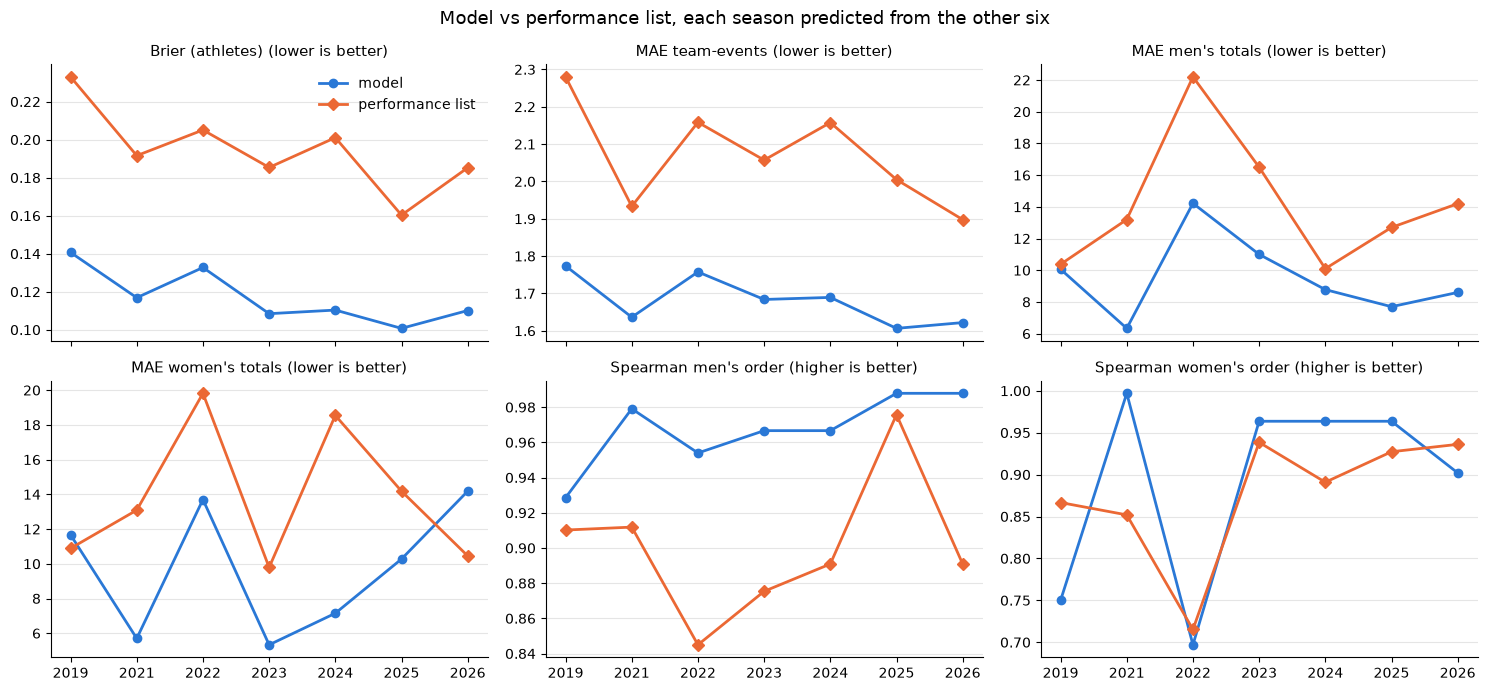

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True)
for ax, (name, (m, p, better)) in zip(axes.flat, PAIRS.items()):
    ax.plot(S.index.astype(str), S[m], "o-", color=MODEL, lw=2, label="model")
    ax.plot(S.index.astype(str), S[p], "D-", color=PLIST, lw=2, label="performance list")
    ax.set_title(f"{name} ({better} is better)", fontsize=11)
    ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", color="#e5e5e5")
axes[0, 0].legend(frameon=False)
fig.suptitle("Model vs performance list, each season predicted from the other six", fontsize=13)
fig.tight_layout(); plt.show()

In [12]:
TE = pd.concat([r["team_event"].assign(season=t) for t, r in loso.items()], ignore_index=True)
TE["group"] = TE["event"].map(bm.event_group)
TE["model"] = (TE["med"] - TE["actual"]).abs()
TE["performance list"] = (TE["plist_pts"] - TE["actual"]).abs()
by = TE.groupby(["group", "season"])[["model", "performance list"]].mean()
eg = TE.groupby("group")[["model", "performance list"]].mean()
eg["seasons model better"] = (by["model"] < by["performance list"]).groupby("group").sum().astype(int).astype(str) + " of 7"
print("Points error per team-event by event type, all seven seasons")
display(eg.sort_values("performance list").round(2))

Points error per team-event by event type, all seven seasons


,model,performance list,seasons model better
group,,,
relay,1.51,1.76,5 of 7
throw,1.59,1.78,5 of 7
sprint,1.59,2.07,7 of 7
horizontal,1.99,2.41,7 of 7
vertical,1.79,2.43,7 of 7
distance,1.67,2.52,7 of 7
multi,2.27,3.31,5 of 7


**Reading the seven seasons**

- **Athletes, team-events, men's totals and men's finishing order:** the model is better in all seven
  seasons. These are consistent gains, not a lucky year. On average the model's men's totals are 9.5
  points off against the list's 14.2.
- **Women's team totals:** the model is better in 5 of 7 seasons (9.7 points off on average, against the
  list's 13.8). The two exceptions are 2019 and 2026, which is why the 2026 table above looks worse for
  women than the seven-season picture does.
- **Women's finishing order:** close to a tie (model better in 4 of 7 seasons, averages 0.89 vs 0.88).
- **By event type,** the model is better in every season for sprints, distance, horizontal jumps and the
  jumps over a bar, and in 5 of 7 seasons for relays, throws and multis.

## 7. Are the model's probabilities trustworthy?

If the model says an athlete has a 30% chance of scoring, then among all athletes it gave about 30%,
roughly 30% should actually score. This is called **calibration**. The chart groups every athlete-event
from the seven seasons by the model's predicted chance and compares it with how often those athletes
really scored. Points on the dashed diagonal mean the probabilities can be taken at face value. Bigger
dots are groups with more athletes.

,athletes,predicted,actual
0-10%,1275,0.031,0.037
10-20%,553,0.149,0.099
20-30%,419,0.248,0.174
30-40%,387,0.349,0.326
40-50%,371,0.450,0.447
50-60%,325,0.546,0.582
60-70%,285,0.651,0.730
70-80%,343,0.752,0.781
80-90%,508,0.854,0.880
90-100%,791,0.953,0.962


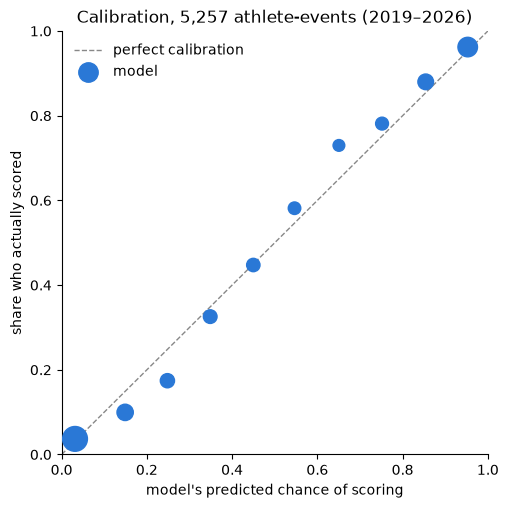

overall: predicted 0.444 of athletes would score, actual 0.445


In [13]:
A = pd.concat([r["athletes"].assign(season=t) for t, r in loso.items()], ignore_index=True)
A["scored"] = A["actual_pts"] > 0
A["bin"] = (A["p_score"] * 10).clip(0, 9).astype(int)
calib = A.groupby("bin").agg(athletes=("scored", "size"), predicted=("p_score", "mean"), actual=("scored", "mean"))
calib.index = [f"{10*b}-{10*b+10}%" for b in calib.index]
display(calib.round(3))

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot([0, 1], [0, 1], ls="--", color="#888", lw=1, label="perfect calibration")
ax.scatter(calib["predicted"], calib["actual"], s=calib["athletes"] / 4, color=MODEL, zorder=3, label="model")
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="model's predicted chance of scoring", ylabel="share who actually scored",
       title=f"Calibration, {len(A):,} athlete-events (2019–2026)")
ax.legend(frameon=False, loc="upper left"); ax.spines[["top", "right"]].set_visible(False)
plt.show()
print(f"overall: predicted {A['p_score'].mean():.3f} of athletes would score, actual {A['scored'].mean():.3f}")

**Reading the calibration**

- **Overall, the chances add up:** the model expected 44.4% of entrants to score and 44.5% did.
- **The extremes are well calibrated:** below 10% and above 80%, predicted and actual rates are within
  about 3 percentage points.
- **In between, the model is a little too cautious.** Athletes given a 10–30% chance scored only about
  10–17% of the time, and athletes given a 50–70% chance scored about 58–73% of the time. In other words,
  the model leans slightly toward "anything can happen": its probabilities for outsiders are a bit high
  and for likely scorers a bit low. The pattern is mild and the same at every level of the chart.

## 8. UC San Diego

UC San Diego joined the Big West in 2025, so it has two championships in the data. These rows come from
the seven-season test above (each season predicted without seeing that championship).

In [14]:
ucsd = pd.concat([r["totals"].assign(season=t) for t, r in loso.items()])
ucsd = ucsd[ucsd["team"] == "UC SAN DIEGO"]
ucsd = ucsd.assign(**{"80% range": ucsd["lo80"].round(0).astype(int).astype(str) + "–" + ucsd["hi80"].round(0).astype(int).astype(str)})
display(ucsd[["season", "gender", "actual", "med", "80% range", "plist_pts"]]
        .rename(columns={"med": "model best guess", "plist_pts": "performance list"}).round(1).reset_index(drop=True))

ev = pd.concat([r["team_event"].assign(season=t) for t, r in loso.items()])
ev = ev[(ev["team"] == "UC SAN DIEGO") & (ev["season"] == 2026)]
ev = ev.assign(**{"80% range": ev["lo80"].round(0).astype(int).astype(str) + "–" + ev["hi80"].round(0).astype(int).astype(str)})
print("UC San Diego, 2026, by event (events where UCSD had an entrant)")
display(ev[["gender", "event", "actual", "med", "80% range", "plist_pts"]]
        .rename(columns={"med": "model best guess", "plist_pts": "performance list"})
        .sort_values(["gender", "actual"], ascending=[True, False]).round(1).reset_index(drop=True))

,season,gender,actual,model best guess,80% range,performance list
0,2025,M,36.0,51.0,38–65,46.0
1,2025,W,75.5,61.0,46–76,54.0
2,2026,M,77.5,76.0,61–92,66.0
3,2026,W,84.0,78.0,62–94,72.0


UC San Diego, 2026, by event (events where UCSD had an entrant)


,gender,event,actual,model best guess,80% range,performance list
0,M,HJ,10.0,11.0,8–15,14.0
1,M,SP,9.0,9.0,4–14,11.0
2,M,TJ,9.0,10.0,5–16,12.0
3,M,4x400,8.0,3.0,0–6,2.0
4,M,DT,8.0,6.0,2–10,5.0
5,M,LJ,8.0,4.0,0–10,4.0
6,M,JT,6.0,2.0,0–6,0.0
7,M,1500,5.0,4.0,0–8,0.0
8,M,4x100,5.0,5.0,0–6,5.0
9,M,PV,3.5,3.0,0–6,1.0


**Reading the UC San Diego results**

- **2026:** the model was within 2 points of the men's score (76 predicted, 77.5 actual) and 6 points of
  the women's (78 predicted, 84 actual). The performance list was 11.5 and 12 points off.
- **2025:** the model was further off: it expected 51 for the men (actual 36) and 61 for the women
  (actual 75.5). The list was closer for the men (46) and further off for the women (54).
- **Both 2026 totals fell inside the model's 80% range.** In 2025 the men's score fell just below the
  range and the women's sat at its top edge.

## 9. Where the model struggles

**Team-wide swings.** In some seasons a few teams have a whole meet that is much better or worse than
their regular season suggests, with most of their athletes missing in the same direction. The model
treats each athlete's day as mostly independent, so it cannot see these swings coming. Testing showed
they are not predictable from past seasons either: a team that over-performed one year often
under-performed the next. These swings explain most of the large team-total misses, including the
women's results in 2022 and 2026.

The table lists every team total in the seven seasons that the model missed by 20 or more points.

In [15]:
T = pd.concat([r["totals"].assign(season=t) for t, r in loso.items()], ignore_index=True)
T["model error"] = T["med"] - T["actual"]
T["list error"] = T["plist_pts"] - T["actual"]
big = T[T["model error"].abs() >= 20].sort_values("model error")
display(big[["season", "gender", "team", "actual", "med", "plist_pts", "model error", "list error"]]
        .rename(columns={"med": "model best guess", "plist_pts": "performance list"}).round(1).reset_index(drop=True))
print(f"{len(big)} of {len(T)} team totals missed by 20+ points; "
      f"the performance list missed {int((T['list error'].abs() >= 20).sum())} by 20+ points")

,season,gender,team,actual,model best guess,performance list,model error,list error
0,2022,M,CAL ST. FULLERTON,200.0,168.0,153.0,-32.0,-47.0
1,2019,W,UC SANTA BARBARA,123.0,93.0,114.0,-30.0,-9.0
2,2023,M,CAL ST. FULLERTON,184.5,155.0,161.0,-29.5,-23.5
3,2022,W,HAWAII,108.0,85.0,80.0,-23.0,-28.0
4,2026,W,CAL ST. FULLERTON,126.0,103.0,114.0,-23.0,-12.0
5,2024,W,CAL POLY,130.8,108.0,93.0,-22.8,-37.8
6,2026,W,UC IRVINE,187.5,166.0,178.0,-21.5,-9.5
7,2023,M,LONG BEACH ST.,182.5,161.0,201.0,-21.5,18.5
8,2022,W,UC RIVERSIDE,63.0,42.0,38.0,-21.0,-25.0
9,2026,M,CAL POLY,201.5,181.0,168.0,-20.5,-33.5


19 of 135 team totals missed by 20+ points; the performance list missed 25 by 20+ points


The model missed 19 of the 135 team totals by 20 or more points; the performance list missed 25.

**Other known limits**

- **Relays.** Predicting relays from their season best made them more accurate, but team totals did not
  improve with it: in some seasons the old relay errors had happened to cancel errors in other events.
- **Upsets in a single race.** An athlete predicted at 2 points sometimes wins. The model gives these
  outcomes a small chance, which is the best a forecast can do; they still produce large individual misses.
- **Heptathlon and decathlon.** Many multi-event athletes have only one score before the championship.
  If that score was a poor day, the model under-predicts them, and nothing else in the regular season
  corrects it.
- **Athletes with no marks.** A few entrants each year have no regular-season marks. The model places them
  near the lower-middle of the field with a wide range, which is a guess.

## 10. Summary

- **The model beats the performance list in every season** at the athlete level (Brier score), at the
  team-event level (MAE), and for men's team totals.
- **Its probabilities can mostly be taken at face value:** the predicted share of scorers matches the
  real share (44.4% vs 44.5%). The model is slightly too cautious in the middle: outsiders are rated a
  little high and likely scorers a little low.
- **Women's team totals are the weak spot:** the model is better than the list in 5 of 7 seasons, but
  not in 2019 or 2026. The large misses come from whole-team swings that neither the model nor the list
  can foresee.
- **Every event type now favors the model in most seasons,** including relays, which are predicted from
  each relay's season best.
- **What the model adds beyond accuracy:** a range and a probability for every athlete, event and team,
  such as each team's chance of winning, which the performance list cannot give.